## Decision Trees
[Decision tree learning](https://en.wikipedia.org/wiki/Decision_tree_learning) is a supervised learning approach used in statistics, data mining and machine learning. A classification or regression decision tree is used as a predictive model to draw conclusions about a set of observations.
<p>
Met een beslisboom kun je dus ook voorspellingen maken, net als met regressie of Naive Bayes Classification.
<p>
Om deze methode te kunnen toepassen, lezen we eerst weer de benodigde libraries in:




In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split

from sklearn import metrics
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn import tree

# Voorbeeld 1: Irissen
We gebruiken een beroemde dataset: de [Iris Flower](https://en.wikipedia.org/wiki/Iris_flower_data_set) data set.

In [ ]:
from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier, export_graphviz
import graphviz

In [ ]:
iris = load_iris()
X = iris.data
y = iris.target

iris

{'data': array([[5.1, 3.5, 1.4, 0.2],
        [4.9, 3. , 1.4, 0.2],
        [4.7, 3.2, 1.3, 0.2],
        [4.6, 3.1, 1.5, 0.2],
        [5. , 3.6, 1.4, 0.2],
        [5.4, 3.9, 1.7, 0.4],
        [4.6, 3.4, 1.4, 0.3],
        [5. , 3.4, 1.5, 0.2],
        [4.4, 2.9, 1.4, 0.2],
        [4.9, 3.1, 1.5, 0.1],
        [5.4, 3.7, 1.5, 0.2],
        [4.8, 3.4, 1.6, 0.2],
        [4.8, 3. , 1.4, 0.1],
        [4.3, 3. , 1.1, 0.1],
        [5.8, 4. , 1.2, 0.2],
        [5.7, 4.4, 1.5, 0.4],
        [5.4, 3.9, 1.3, 0.4],
        [5.1, 3.5, 1.4, 0.3],
        [5.7, 3.8, 1.7, 0.3],
        [5.1, 3.8, 1.5, 0.3],
        [5.4, 3.4, 1.7, 0.2],
        [5.1, 3.7, 1.5, 0.4],
        [4.6, 3.6, 1. , 0.2],
        [5.1, 3.3, 1.7, 0.5],
        [4.8, 3.4, 1.9, 0.2],
        [5. , 3. , 1.6, 0.2],
        [5. , 3.4, 1.6, 0.4],
        [5.2, 3.5, 1.5, 0.2],
        [5.2, 3.4, 1.4, 0.2],
        [4.7, 3.2, 1.6, 0.2],
        [4.8, 3.1, 1.6, 0.2],
        [5.4, 3.4, 1.5, 0.4],
        [5.2, 4.1, 1.5, 0.1],
  

## Beslisboom
We gaan kijken of we een beslisboom kunnen maken die op basis van de lengte en breedte van het kelkblad (sepal) en het bloemblad (petal) de soort iris kan voorspellen.

[Text(0.28804347826086957, 0.9444444444444444, 'sepal length (cm) <= 42.35\ngini = 0.638\nsamples = 334\nvalue = [146, 68, 120]\nclass = setosa'),
 Text(0.08695652173913043, 0.8333333333333334, 'sepal width (cm) <= 15.1\ngini = 0.057\nsamples = 138\nvalue = [134, 1, 3]\nclass = setosa'),
 Text(0.043478260869565216, 0.7222222222222222, 'gini = 0.0\nsamples = 3\nvalue = [0, 0, 3]\nclass = virginica'),
 Text(0.13043478260869565, 0.7222222222222222, 'sepal width (cm) <= 16.65\ngini = 0.015\nsamples = 135\nvalue = [134, 1, 0]\nclass = setosa'),
 Text(0.08695652173913043, 0.6111111111111112, 'sepal length (cm) <= 39.5\ngini = 0.165\nsamples = 11\nvalue = [10, 1, 0]\nclass = setosa'),
 Text(0.043478260869565216, 0.5, 'gini = 0.0\nsamples = 10\nvalue = [10, 0, 0]\nclass = setosa'),
 Text(0.13043478260869565, 0.5, 'gini = 0.0\nsamples = 1\nvalue = [0, 1, 0]\nclass = versicolor'),
 Text(0.17391304347826086, 0.6111111111111112, 'gini = 0.0\nsamples = 124\nvalue = [124, 0, 0]\nclass = setosa'),
 T

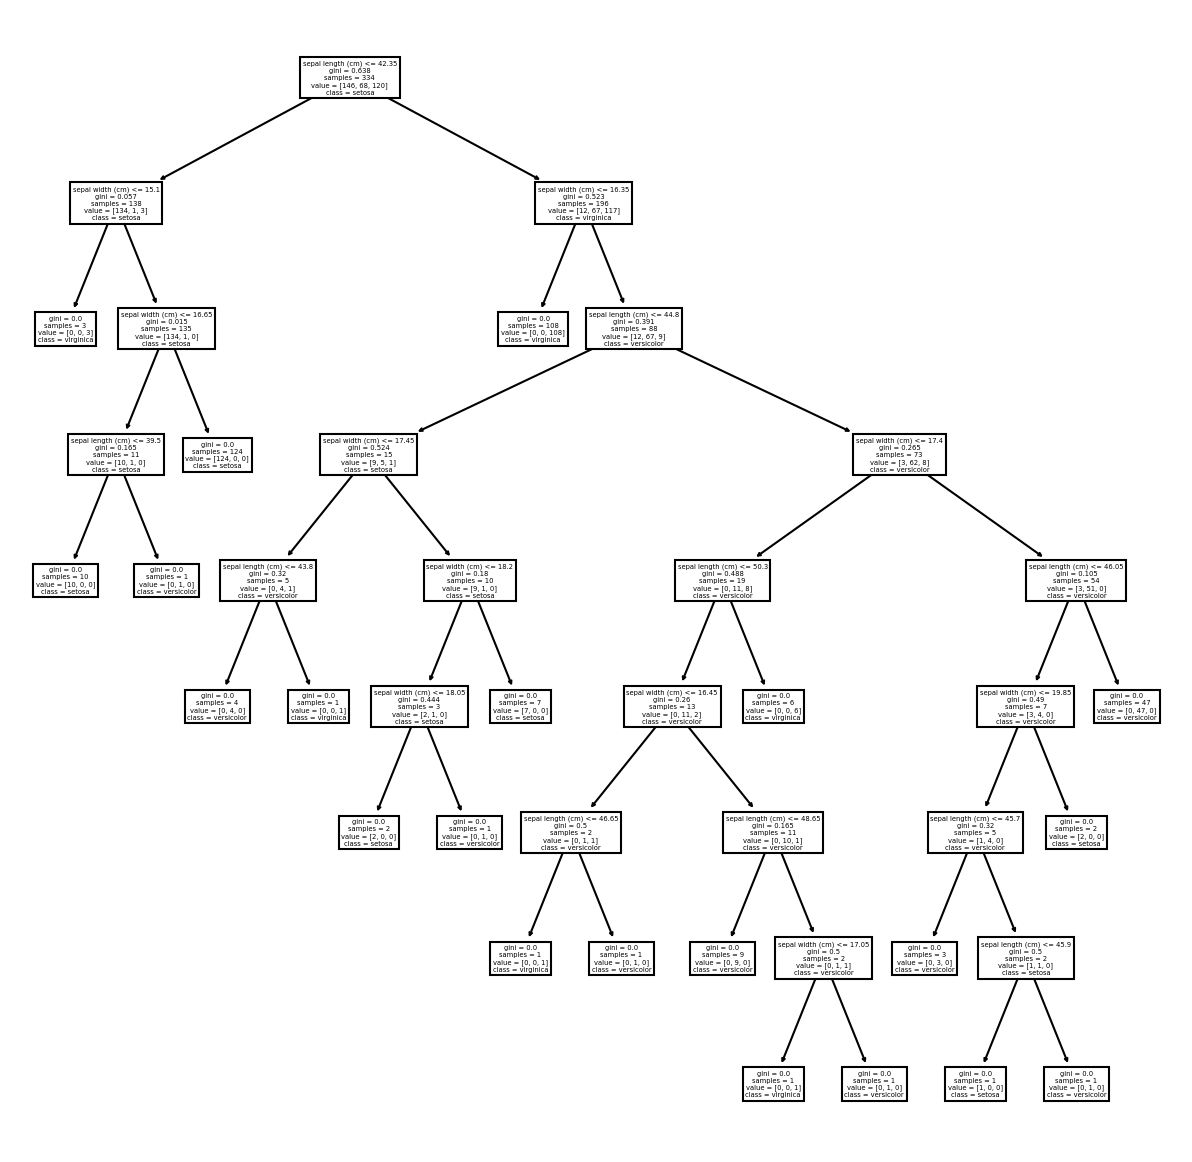

In [ ]:
clf = DecisionTreeClassifier()
clf.fit(X, y)

plt.figure(figsize = (10, 10), dpi = 150)
tree.plot_tree(clf,feature_names=iris.feature_names, class_names=iris.target_names)

We kunnen de boom ook exporteren naar een pdf-bestand, inclusief mooie kleuren:

In [ ]:
dot_data = export_graphviz(clf, out_file=None,
                     feature_names=iris.feature_names,
                     class_names=iris.target_names,
                     filled=True, rounded=True,
                     special_characters=True)

graph = graphviz.Source(dot_data)
graph.render("iris")

'iris.pdf'

# Voorbeeld 2: Pinguins
Via panda's wordt het bestand penguins_size.csv ingelezen.

De NaN's worden uit de dataframe gehaald:


In [ ]:
# =====================Inladen bestanden=======================================
# Tabellen met parameters ophalen uit dit bestand.
df = pd.read_csv("penguins_size.csv")
# =============================================================================
df = df.dropna()
df

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,MALE
...,...,...,...,...,...,...,...
338,Gentoo,Biscoe,47.2,13.7,214.0,4925.0,FEMALE
340,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,FEMALE
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,MALE
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,FEMALE


In [ ]:
df.describe()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
count,334.000000,334.000000,334.000000,334.000000
mean,43.994311,17.160479,201.014970,4209.056886
std,5.460521,1.967909,14.022175,804.836129
min,32.100000,13.100000,172.000000,2700.000000
25%,39.500000,15.600000,190.000000,3550.000000
50%,44.500000,17.300000,197.000000,4050.000000
75%,48.575000,18.700000,213.000000,4793.750000
max,59.600000,21.500000,231.000000,6300.000000


## Beslisboom voor Classificatie
Laten we eens kijken of we een voorspelling kunnen maken.
<p>
Dat doen we door eerst de data te verdelen in een trainings-set (40%) en een test-set (60%). Met de trainings-set 'train' je het model = laat je het model berekenen welke pinguin bij welke snavellengte- en diepte hoort.
<p>
Met de test-set voorspel je vervolgens welke pinguin bij welke snavellengte- en diepte hoort.   

In [ ]:
X = df.iloc[:,2:4]
y = df.iloc[:,0]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.6, random_state=42)

Vervolgens trainen we het model:

[Text(0.4, 0.9375, 'culmen_depth_mm <= 16.4\ngini = 0.638\nsamples = 133\nvalue = [54, 26, 53]\nclass = y[0]'),
 Text(0.2, 0.8125, 'culmen_length_mm <= 37.05\ngini = 0.038\nsamples = 52\nvalue = [1, 0, 51]\nclass = y[2]'),
 Text(0.1, 0.6875, 'gini = 0.0\nsamples = 1\nvalue = [1, 0, 0]\nclass = y[0]'),
 Text(0.3, 0.6875, 'gini = 0.0\nsamples = 51\nvalue = [0, 0, 51]\nclass = y[2]'),
 Text(0.6, 0.8125, 'culmen_length_mm <= 42.35\ngini = 0.468\nsamples = 81\nvalue = [53, 26, 2]\nclass = y[0]'),
 Text(0.5, 0.6875, 'gini = 0.0\nsamples = 49\nvalue = [49, 0, 0]\nclass = y[0]'),
 Text(0.7, 0.6875, 'culmen_depth_mm <= 20.15\ngini = 0.32\nsamples = 32\nvalue = [4, 26, 2]\nclass = y[1]'),
 Text(0.6, 0.5625, 'culmen_length_mm <= 54.3\ngini = 0.24\nsamples = 30\nvalue = [2, 26, 2]\nclass = y[1]'),
 Text(0.5, 0.4375, 'culmen_length_mm <= 44.65\ngini = 0.19\nsamples = 29\nvalue = [2, 26, 1]\nclass = y[1]'),
 Text(0.3, 0.3125, 'culmen_length_mm <= 42.85\ngini = 0.48\nsamples = 5\nvalue = [2, 3, 0]\nc

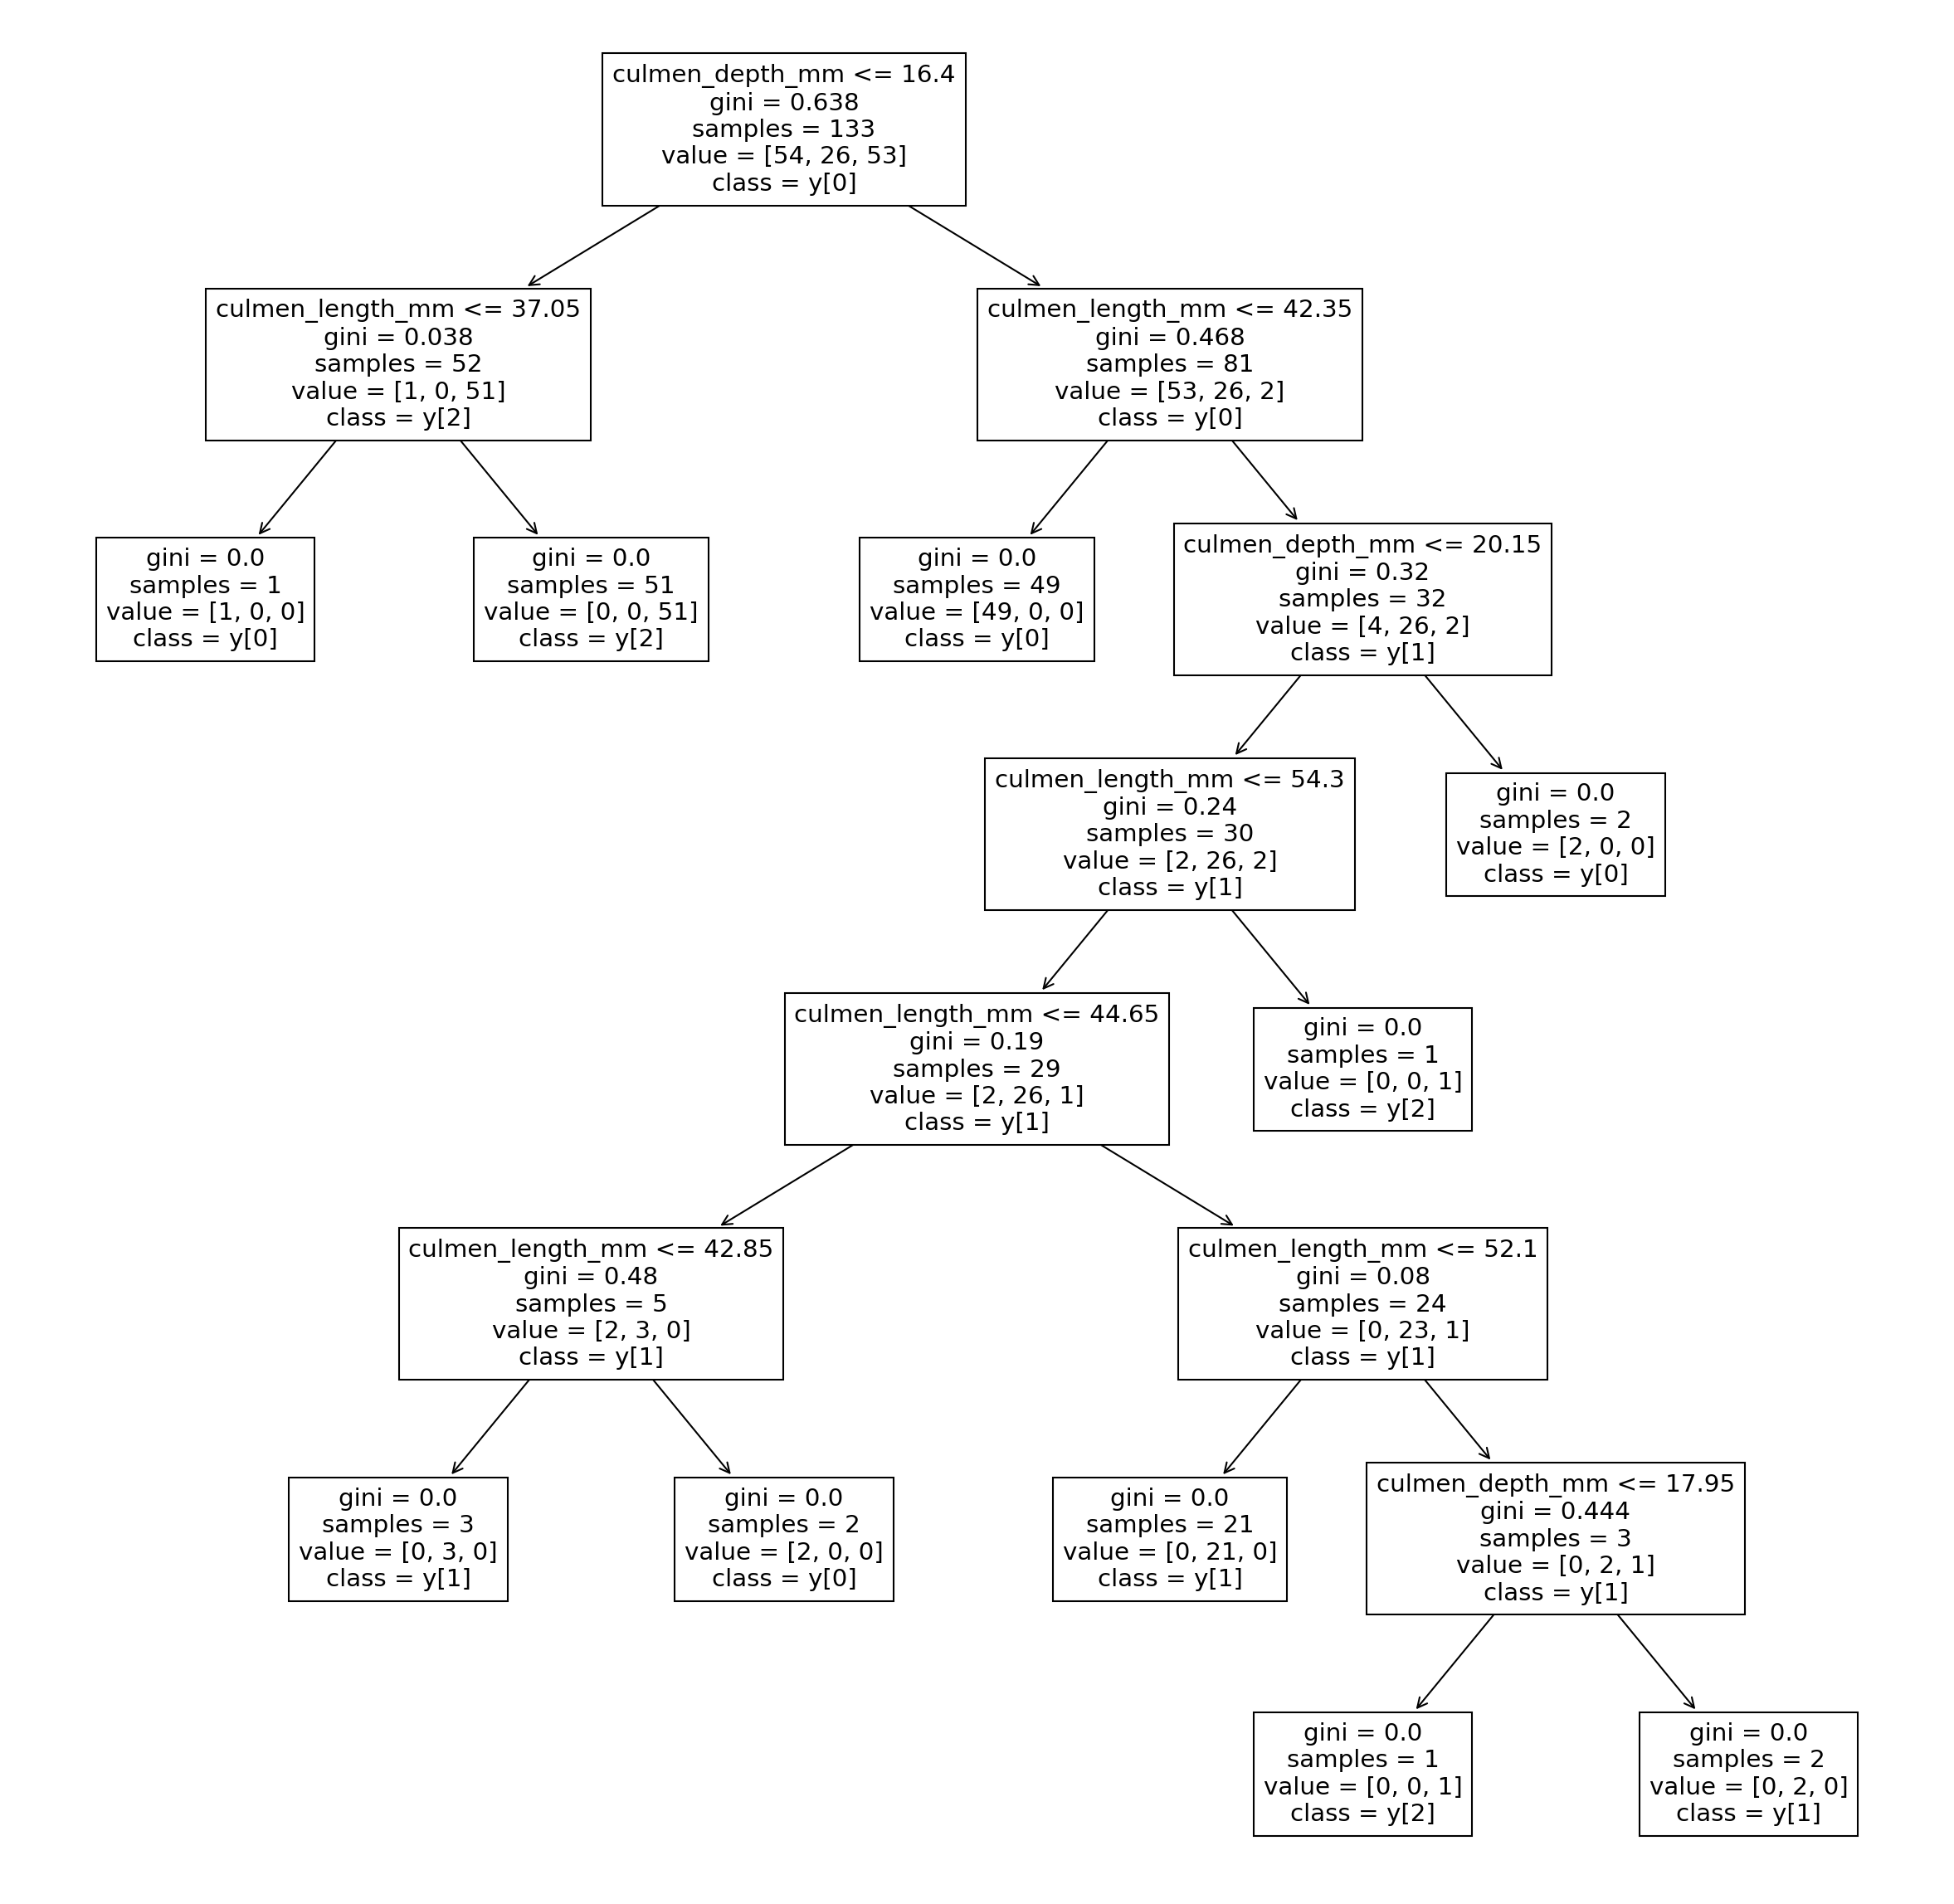

In [ ]:
clf = DecisionTreeClassifier()
dtree = clf.fit(X_train, y_train)

plt.figure(figsize = (20, 20), dpi = 150)
tree.plot_tree(dtree, feature_names = ['culmen_length_mm','culmen_depth_mm'], class_names = True)

We kunnen ook deze boom als pdf opslaan:

In [ ]:
dot_data = export_graphviz(dtree, out_file=None, feature_names = df.columns[2:4], class_names = df['species'].unique(),
                     filled=True, rounded=True,
                     special_characters=True)

graph = graphviz.Source(dot_data)
graph.render("pinguins")

'pinguins.pdf'

Is deze beslisboom nu een goede voorspeller?

In [ ]:
prediction = dtree.predict(X_test)

df2 = pd.DataFrame()

df2['Species'] = y_test
df2['Predicted Species'] = prediction
df2

,Species,Predicted Species
30,Adelie,Adelie
317,Gentoo,Gentoo
79,Adelie,Adelie
201,Chinstrap,Chinstrap
63,Adelie,Adelie
...,...,...
40,Adelie,Adelie
33,Adelie,Adelie
176,Chinstrap,Chinstrap
148,Adelie,Adelie


In [ ]:
-print('Accuracy:', accuracy_score(y_test, prediction).round(4))

Accuracy: 0.9104


Een accuratesse van 91,04 %, dat is wat lager dan bij de Naive Bayes Classification.

## Confusion matrix
De confusion matrix laat zien dat er 16 pinguins verkeerd voorspeld worden:

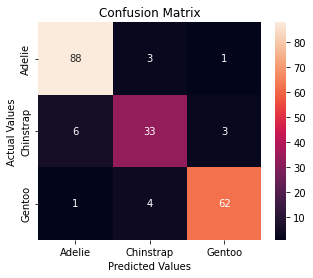

In [ ]:
cm = confusion_matrix(y_test, prediction)
cm_df = pd.DataFrame(cm,
                     index = ['Adelie','Chinstrap','Gentoo'],
                     columns = ['Adelie','Chinstrap','Gentoo'])

#Plotting the confusion matrix
plt.figure(figsize=(5,4))
sns.heatmap(cm_df, annot=True, fmt='g')
plt.title('Confusion Matrix')
plt.ylabel('Actual Values')
plt.xlabel('Predicted Values')
plt.show()

In [ ]:
print("Number of mislabeled points out of a total %d points : %d"
      % (X_test.shape[0], (y_test != prediction).sum()))

Number of mislabeled points out of a total 201 points : 18


# Voorbeeld 3 Pinguins
We kunnnen een beslisboom ook gebruiken bij het voorspellen van een continue variabele. In dit voorbeeld gaan we kijken of we het gewicht (bodymass) van een pinguin kunnen voorspellen op basis van flipperlengte, snavellengte en snaveldiepte.

In onderstaand scatterplot wordt de flipperlengte en het gewicht tegen elkaar uitgezet.

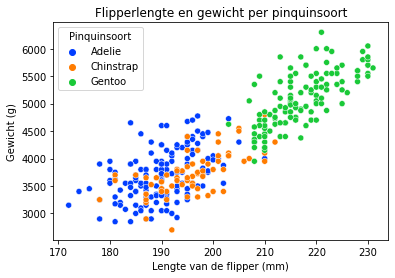

In [ ]:
sns.set_palette("bright")
ax = sns.scatterplot(x='flipper_length_mm',
                     y='body_mass_g',
                     data=df,
                     hue='species')
plt.title('Flipperlengte en gewicht per pinquinsoort', color='black')
plt.xlabel('Lengte van de flipper (mm)')
plt.ylabel('Gewicht (g)')
plt.legend(title='Pinquinsoort')
plt.show()

In de scatterplot zien we duidelijk 1 groep die op basis van de flipperlengte en het gewicht eruit springt: de Gentoo's. De andere 2 pinguinsoorten (Adelie en Chinstrap) lopen door elkaar heen en zijn op basis van alleen de flipperlengte en het gewicht niet te onderscheiden.

## Beslisboom voor Regressie
Omdat het gewicht voorspellen op basis van alleen de flipperlengte niet gaat werken, gebruiken we ook de snavellengte en -diepte voor het voorspelmodel. Verder verdelen we de data weer in een training-(60%) en test-set (40%):

In [ ]:
X = df.iloc[:,2:5]
y = df.iloc[:,5]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=42)

We trainen het model:

In [ ]:
RegModel = tree.DecisionTreeRegressor(max_depth=3,criterion='friedman_mse')

DTree = RegModel.fit(X_train, y_train)

prediction = DTree.predict(X_test)

print('R2 Value:' ,(metrics.r2_score(y_train, DTree.predict(X_train))).round(3))

print('Accuracy:', (100-(np.mean(np.abs((y_test - prediction) / y_test))*100)).round(3))

R2 Value: 0.838
Accuracy: 92.602


Een accuratesse van 92,6%, dat is vergelijkbaar met de classificatie-beslisboom (zie boven).

In [ ]:
df3 = pd.DataFrame()

df3['body_mass_g'] = y_test
df3['Predicted Mass'] = prediction.round(2)
df3

,body_mass_g,Predicted Mass
30,3250.0,3512.07
317,4875.0,5055.56
79,4000.0,3962.98
201,3675.0,3512.07
63,4050.0,3962.98
...,...,...
214,3650.0,3512.07
102,3075.0,3211.76
103,4250.0,3571.05
204,3600.0,3512.07


Het gewicht zal nooit precies voorspeld worden, maar we kunnen wel berekenen hoe groot de procentuele afwijking tussen werkelijke en voorspelde waarde is:

In [ ]:
weight = df3[['body_mass_g', 'Predicted Mass']].pct_change(axis = 'columns', periods = 1 ).abs()
total = sum(weight['Predicted Mass'])

average_miscalc = (total / len(weight)) * 100
print(f"De afwijking tussen predicted weight en daadwerkelijk gewicht is gemiddeld {round(average_miscalc, 2)} % \n\n\n" )

De afwijking tussen predicted weight en daadwerkelijk gewicht is gemiddeld 7.4 % 





Een afwijking van 7,4%, dat sluit aan bij de accuratesse-score van 92,6%.

# Intermezzo: How to control the Tree?
We need some way to determine when to stop growing a tree at a stage that will generalize to new data. There are various ways to stop splitting in Python:
<p>
• Avoid splitting a partition if a resulting subpartition is too small, or if a terminal leaf is too small. In Python’s DecisionTreeClassifier, we can control this using the parameters <b>min_samples_split</b> (default 2) and <b>min_samples_leaf</b> (default 1).<br>
• Don’t split a partition if the new partition does not “significantly” reduce the impurity. DecisionTreeClassifier (Python) has the parameter
<b>min_impurity_decrease</b>, which limits splitting based on a weighted impurity
decrease value. Here, smaller values will lead to more complex trees.
<p>
<b>Controlling tree complexity in Python</b><br>
Neither the complexity parameter nor pruning is available in scikit-learn’s decision tree implementation. The solution is to use grid search over combinations of different parameter values. For example, we can vary <b>max_depth</b> in the range 5 to 30 and <b>min_samples_split</b> between 20 and 100.
<p>
The <b>GridSearchCV</b>-method in scikitlearn is a convenient way to combine the exhaustive search through all combinations with cross-validation. An optimal parameter set is then selected using the crossvalidated model performance.

# Voorbeeld 4 VU studentendataset
Nu kijken of we deze techniek kunnen toepassen op onze VU studentendata.<br>
We gaan kijken of we het model kunnen 'leren' om op basis van het aantal vrienden de 'happiness' te voorspellen.

Eerst inlezen van een selectie (twee kolommen: nofriend en ls) van de data.

In [ ]:
df = pd.read_excel("vustudentanalytics.xlsx")
df = df.loc[:, ["nofriend", "ls"]]
df.head() # We take a look at the first 5 rows


,nofriend,ls
0,6,PLEASED
1,4,MOSTLY SATISFIED
2,20,PLEASED
3,0,MIXED
4,6,MOSTLY SATISFIED


In [ ]:
df.shape

(5000, 2)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   nofriend  5000 non-null   int64 
 1   ls        4992 non-null   object
dtypes: int64(1), object(1)
memory usage: 78.2+ KB


We zien dat er 5.000 regels in de dataset zitten, maar in de ls-kolom ontbreken er waarden.<p>
Om een beslisboom te kunnen maken, mogen er geen NULL of NaN waarden in de tabel zitten.<p>
Die gaan we dus eerst verwijderen.

In [ ]:
df_analyse = df.dropna()
df_analyse.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 4992 entries, 0 to 4999
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   nofriend  4992 non-null   int64 
 1   ls        4992 non-null   object
dtypes: int64(1), object(1)
memory usage: 117.0+ KB


We houden 4.992 regels over. Met deze selectie gaan we nu verder.<p>


Nog even een plaatje:

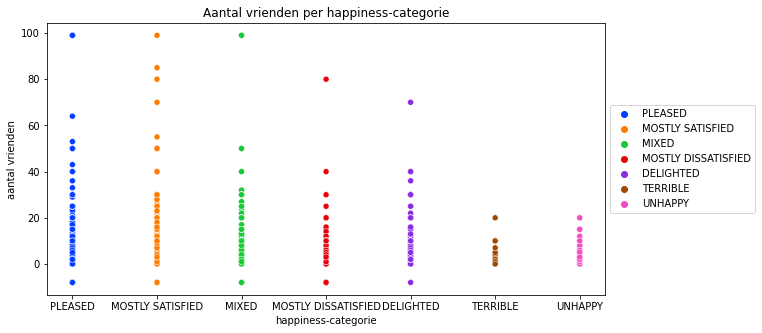

In [ ]:
sns.set_palette("bright")
plt.figure(figsize=(10,5))
ax = sns.scatterplot(x='ls',
                     y='nofriend',
                     data=df_analyse,
                     hue='ls')
plt.title('Aantal vrienden per happiness-categorie', color='black')
plt.xlabel('happiness-categorie')
plt.ylabel('aantal vrienden')
plt.legend(title='Happiness-categorie')
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.show()

## Beslisboom
We trainen en testen het model:

[Text(0.296875, 0.9583333333333334, 'x[0] <= 4.5\ngini = 0.699\nsamples = 1996\nvalue = [71, 343, 105, 671, 783, 10, 13]\nclass = y[4]'),
 Text(0.11428571428571428, 0.875, 'x[0] <= 1.5\ngini = 0.72\nsamples = 887\nvalue = [20, 190, 65, 309, 290, 5, 8]\nclass = y[3]'),
 Text(0.05714285714285714, 0.7916666666666666, 'x[0] <= -4.0\ngini = 0.754\nsamples = 220\nvalue = [5, 62, 26, 56, 65, 3, 3]\nclass = y[4]'),
 Text(0.02857142857142857, 0.7083333333333334, 'gini = 0.514\nsamples = 12\nvalue = [0, 1, 1, 2, 8, 0, 0]\nclass = y[4]'),
 Text(0.08571428571428572, 0.7083333333333334, 'x[0] <= 0.5\ngini = 0.756\nsamples = 208\nvalue = [5, 61, 25, 54, 57, 3, 3]\nclass = y[1]'),
 Text(0.05714285714285714, 0.625, 'gini = 0.774\nsamples = 109\nvalue = [4, 34, 14, 25, 26, 3, 3]\nclass = y[1]'),
 Text(0.11428571428571428, 0.625, 'gini = 0.729\nsamples = 99\nvalue = [1, 27, 11, 29, 31, 0, 0]\nclass = y[4]'),
 Text(0.17142857142857143, 0.7916666666666666, 'x[0] <= 2.5\ngini = 0.702\nsamples = 667\nvalue 

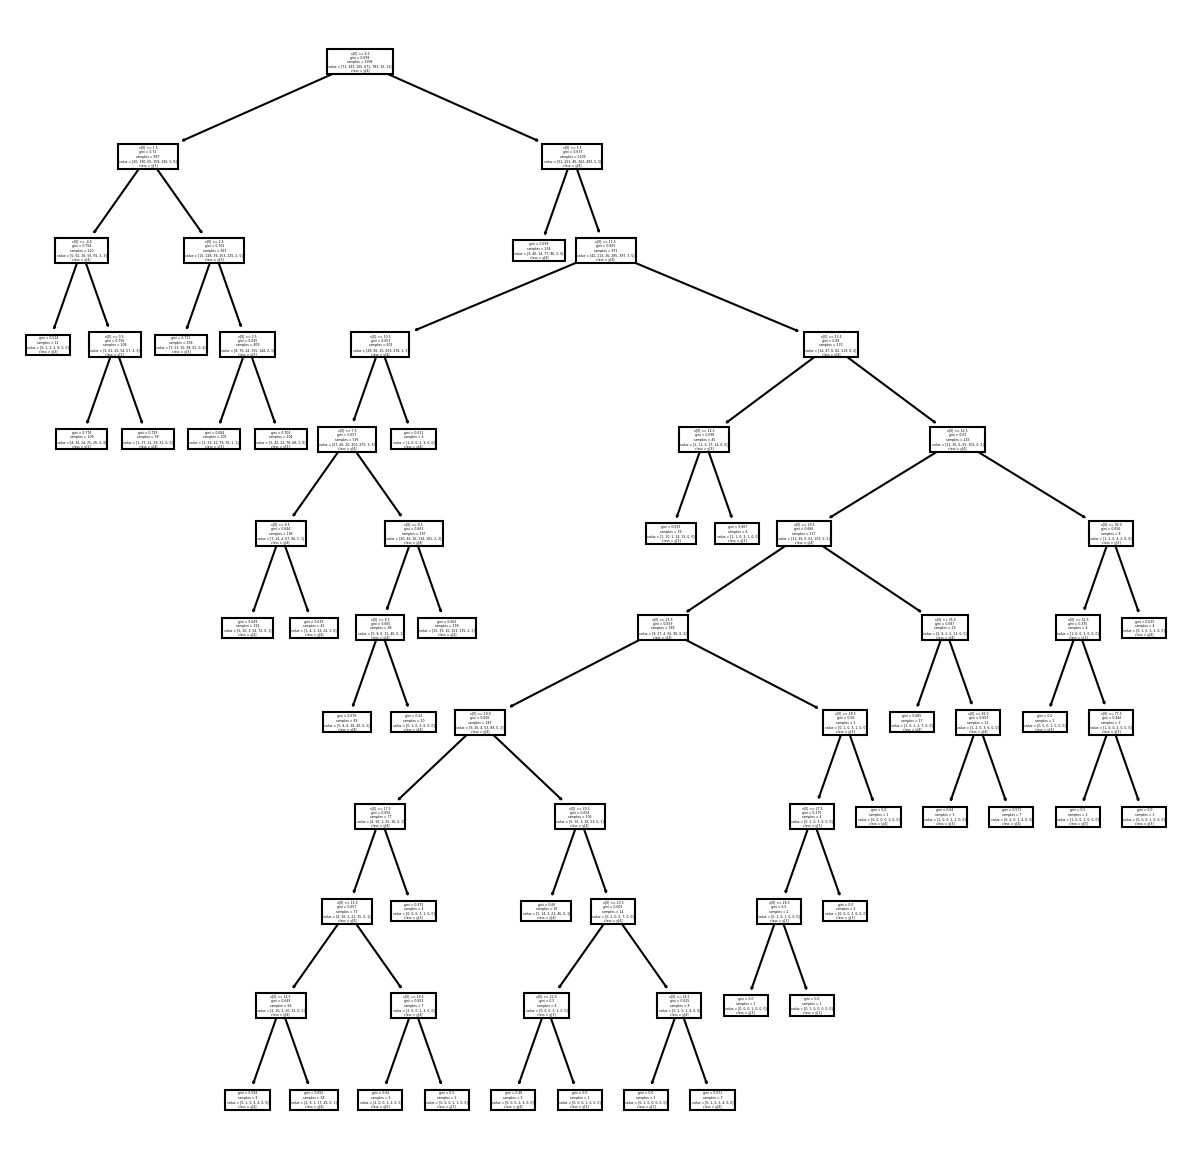

In [ ]:
X = df_analyse.loc[:, ["nofriend"]]
y = df_analyse['ls']

X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                random_state=1,
                                                test_size = 0.6)
clf = DecisionTreeClassifier()
dtree = clf.fit(X_train, y_train)

plt.figure(figsize = (10, 10), dpi = 150)
tree.plot_tree(dtree, feature_names = None, class_names = True)

Opslaan als pdf:

In [ ]:
dot_data = export_graphviz(dtree, out_file=None, feature_names = df.columns[:-1], class_names = df['ls'].unique(),
                     filled=True, rounded=True,
                     special_characters=True)

graph = graphviz.Source(dot_data)
graph.render("happiness")

'happiness.pdf'

Is deze beslisboom nu een goede voorspeller?

In [ ]:
prediction = dtree.predict(X_test)

df4 = pd.DataFrame()

df4['ls'] = y_test
df4['Predicted Happiness'] = prediction
df4

,ls,Predicted Happiness
4493,PLEASED,PLEASED
2989,PLEASED,PLEASED
3027,MOSTLY SATISFIED,MOSTLY SATISFIED
1328,MOSTLY SATISFIED,PLEASED
1687,MOSTLY SATISFIED,PLEASED
...,...,...
1001,PLEASED,MIXED
2319,UNHAPPY,MIXED
4714,MOSTLY DISSATISFIED,MOSTLY SATISFIED
1952,MOSTLY SATISFIED,MOSTLY SATISFIED


In [ ]:
print('Accuracy:', accuracy_score(y_test, prediction).round(4))

Accuracy: 0.3808


De accuratesse houdt niet over: maar 38,08% wordt goed 'voorspeld'.

## Confusion matrix
Tijd voor de confusion matrix:

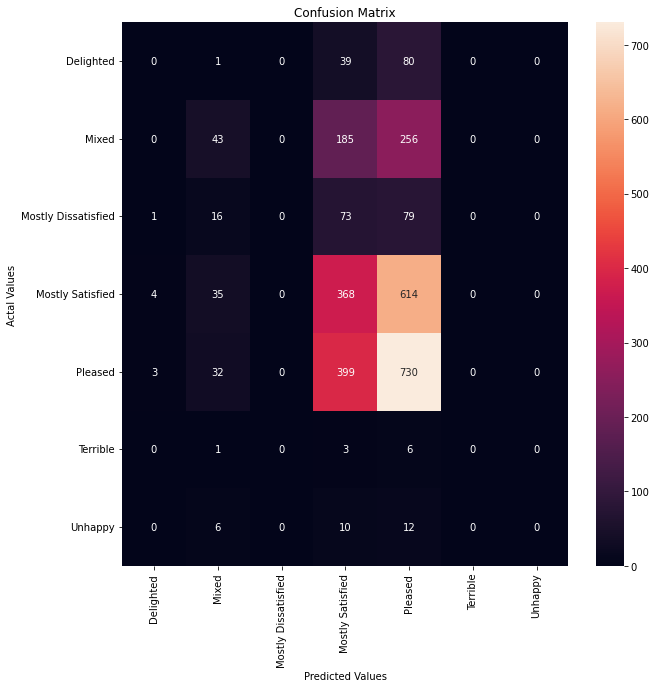

In [ ]:
cm = confusion_matrix(y_test, prediction)
cm_df = pd.DataFrame(cm,
                     index = ['Delighted','Mixed','Mostly Dissatisfied','Mostly Satisfied','Pleased','Terrible','Unhappy'],
                     columns = ['Delighted','Mixed','Mostly Dissatisfied','Mostly Satisfied','Pleased','Terrible','Unhappy'])

#Plotting the confusion matrix
plt.figure(figsize=(10,10))
sns.heatmap(cm_df, annot=True, fmt='g')
plt.title('Confusion Matrix')
plt.ylabel('Actal Values')
plt.xlabel('Predicted Values')
plt.show()

In [ ]:
print("Number of mislabeled points out of a total %d points : %d"
      % (X_test.shape[0], (y_test != prediction).sum()))

Number of mislabeled points out of a total 2996 points : 1855


Ook dit is een waardeloos voorspelmodel:<br>
van de 2.996 personen is er maar van 1.141 personen, op basis van het aantal vrienden, de 'happiness'-score juist voorspeld. In vergelijking met de Naive Bayes Classification worden nu wel 3 categorieen enigszins voorspeld: mixed, mostly satisfied en pleased. Maar is dit model te gebruiken .. mmmm.
<p>
Aan jullie dus ook hier de opdracht:<br>
kijk of er bij jullie onderzoeksvragen, op basis van deze techniek, een goed (= accuraat) voorspelmodel is te maken.

# **Let Op bij de Confusion Matrix**
Als je geen ' labels' bij het confusion_matrix-commando gebruikt, sorteert Python de y-waarden (= de te voorspellen waardes) op alfabetische volgorde (voor zover aanwezig in de testset).
<p>
In het voorbeeld hierboven: eerst de D van Delighted, dan de M van Mixed, dan de M van Mostly Dissatisfied etc.
<p>
Als je de 'verkeerde' volgorde gebruikt, lees je de confusion matrix verkeerd af en krijg je dus ook foutieve conclusies!
<p>
https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html   


# [Random Forest](https://levelup.gitconnected.com/random-forest-regression-209c0f354c84)
Random forests or random decision forests is an ensemble learning method for classification, regression and other tasks that operates by constructing a multitude of decision trees at training time.
<p>
For classification tasks, the output of the random forest is the class selected by most trees.<br>
For regression tasks, the mean or average prediction of the individual trees is returned.<br>
(https://en.wikipedia.org/wiki/Random_forest)

We gebruiken wederom de pinguin-dataset als voorbeeld en lezen eerst de benodigde (extra) library in:

In [ ]:
from sklearn.tree import DecisionTreeRegressor

We definieren een aantal functies die we nodig hebben om het random forest-algoritme te kunnen draaien:<br>
- bootstrap<br>
- random_tree<br>
- rand_tree.fit<br>
- random_forest_list & random_forest_list.append<br>

In [ ]:
def bootstrap(df):
    n_rows = df.shape[0]
    random_rows = np.random.randint(n_rows, size=n_rows)
    return df.iloc[random_rows, :]
dfb = bootstrap(df)

Met de bootstrap-functie selecteren we een willekeurige subset uit onze gehele dataset, die we gebruiken voor het trainen van ons voorspelmodel.
<p>
We selecteren 9x een willekeurige set en maken op basis daarvan een lijst met 9 beslisbomen (van 0 tot 8):

In [ ]:
random_forest_list = []
random_forest_list.append(rand_tree)

for i in range(8):
    dfb = bootstrap(df)
    rand_tree = DecisionTreeRegressor(
        max_features="sqrt"
    )

    rand_tree.fit(
        X=dfb.drop(['species', 'island', 'sex', 'body_mass_g'], axis = 1),
        y=dfb["body_mass_g"]
    )

    random_forest_list.append(rand_tree)

We gaan opnieuw de body-mass voorspellen op basis van snavellengte en -diepte + zwemvlieslengte. We gebruiken het gemiddelde van 9 beslisbomen als voorspeller van de body-mass:

In [ ]:
predictions = []

for i in range(len(df)):
  inputs = pd.DataFrame([{"culmen_length_mm" : df.iloc[i,2], "culmen_depth_mm" : df.iloc[i,3], "flipper_length_mm": df.iloc[i,4]}])
  prediction = 0
  for i, rand_tree in enumerate(random_forest_list):
    prediction += rand_tree.predict(inputs)[0]
  prediction /= 9 # Er zijn 9 bomen gebruikt, hierdoor moet de voorspelling dus worden gedeeld
  prediction = round(prediction, 2)
  predictions.append(prediction)

Hoe ziet de tabel met voorspellingen eruit?

In [ ]:
df3 = pd.DataFrame()

df3['body_mass_g'] = df['body_mass_g']
df3['Predicted Mass'] = predictions

print(df3)

     body_mass_g  Predicted Mass
0         3750.0         3772.22
1         3800.0         3705.56
2         3250.0         3672.22
4         3450.0         3750.00
5         3650.0         3927.78
..           ...             ...
338       4925.0         4863.89
340       4850.0         4894.44
341       5750.0         5583.33
342       5200.0         5100.00
343       5400.0         5447.22

[334 rows x 2 columns]


En hoe goed is de voorspelling?

In [ ]:
weight = df3[['body_mass_g', 'Predicted Mass']].pct_change(axis = 'columns', periods = 1 ).abs()
total = sum(weight['Predicted Mass'])

average_miscalc = (total / len(weight)) * 100
print(f"De afwijking tussen predicted weight en daadwerkelijk gewicht is gemiddeld {round(average_miscalc, 2)} % \n\n\n" )

De afwijking tussen predicted weight en daadwerkelijk gewicht is gemiddeld 2.94 % 





Een afwijking van 2,94%, dat is nog een stuk beter dan met de 'enkelvoudige' beslisboom.

## Nadeel van de Random Forrest-methode
While random forests often achieve higher accuracy than a single decision tree, they sacrifice the intrinsic interpretability present in decision trees.
<p>
Decision trees are among a fairly small family of machine learning models that are easily interpretable along with linear models, rule-based models, and attention-based models. This interpretability is one of the most desirable qualities of decision trees. It allows developers to confirm that the model has learned realistic information from the data and allows end-users to have trust and confidence in the decisions made by the model.
<p>
For example, following the path that a decision tree takes to make its decision is quite trivial, but following the paths of tens or hundreds of trees is much harder.